# ECHO — Case File (Qubits Qrew · NED · The Quantathon)
**Team name:** _<apni team ka naam yahan likho>_  |  **Stretch module chosen:** 04 (The Erased Measurement) + bonus 06

Har module mein: **answer + code + one-line "what it proves"**. Notebook upar se neeche tak run hota hai.

In [1]:
!pip -q install qiskit qiskit-aer matplotlib pylatexenc

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
sim = AerSimulator()
SHOTS = 1000
def run(qc, shots=SHOTS):
    return sim.run(qc, shots=shots).result().get_counts()
print('ready')

ready


## Module 01 — The Gatekeeper (mandatory)
Gates: H, X, measure.

### 🥉 Bronze — always 1, and perfectly uncertain

In [3]:
# always 1: X flips |0> -> |1>
qc = QuantumCircuit(1,1); qc.x(0); qc.measure(0,0)
print('always 1  :', run(qc))

# perfectly uncertain: H puts |0> into (|0>+|1>)/sqrt2
qc = QuantumCircuit(1,1); qc.h(0); qc.measure(0,0)
print('50/50     :', run(qc, 10000))

always 1  : {'1': 1000}
50/50     : {'0': 4953, '1': 5047}


**Proves:** X is deterministic (a bit-flip); H creates a superposition whose measurement is a fair coin (Born rule: each outcome prob = 1/2).

### 🥈 Silver — looks uncertain but is secretly certain: H then H

In [4]:
qc = QuantumCircuit(1,1); qc.h(0); qc.h(0); qc.measure(0,0)
print('H,H ->', run(qc))
# The matrix proof
H = np.array([[1,1],[1,-1]])/np.sqrt(2)
print(np.round(H@H,10))

H,H -> {'0': 1000}
[[ 1. -0.]
 [-0.  1.]]


**Why:** H·H = I. After the first H the qubit is in superposition, but the second H makes the two paths **interfere**: the |1> amplitudes cancel (+1/2 − 1/2 = 0), the |0> amplitudes add (1/2 + 1/2 = 1). So "uncertain in the middle" does not mean "random at the end" — amplitudes (not probabilities) are what combine.

### 🥇 Gold — vault code `101` from `000`

In [5]:
qc = QuantumCircuit(3,3)
qc.x(0); qc.x(2)          # flip qubit 0 and qubit 2 -> |101> (q2 q1 q0 = 1 0 1)
qc.measure([0,1,2],[0,1,2])
print(run(qc))   # Qiskit prints bits as c2 c1 c0 -> '101'

{'101': 1000}


**Proves:** X on the bits that need to be 1, nothing on the rest. Note Qiskit's little-endian ordering (qubit 0 is the rightmost bit); here 101 is a palindrome so it reads the same either way.

## Module 03 — The Two Observers (mandatory · heart of the case)
Gates: H, X, CNOT, measure.

### 🥉 Bronze — a pair that only ever agrees (00 and 11)

{'11': 2031, '00': 1969}


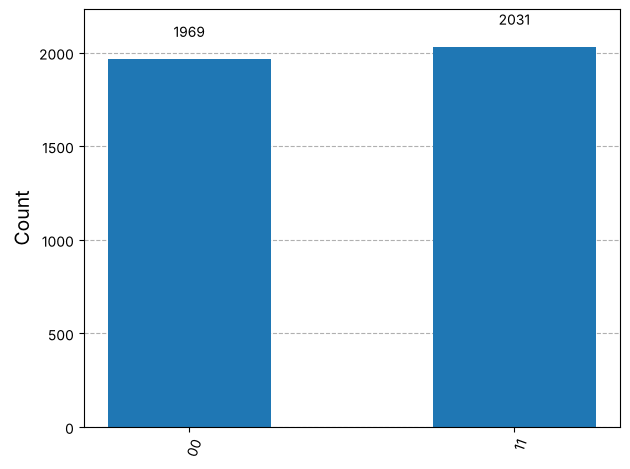

In [6]:
bell = QuantumCircuit(2,2)
bell.h(0); bell.cx(0,1)
bell.measure([0,1],[0,1])
counts = run(bell, 4000); print(counts)
plot_histogram(counts)

**Proves:** H + CNOT makes the Bell state (|00>+|11>)/√2. Outcomes are 00 or 11 (~50/50 each), never 01/10.

### 🥈 Silver — a pre-agreed secret also always agrees

In [7]:
import random
def classical_pair(n=4000):
    out={}
    for _ in range(n):
        secret = random.randint(0,1)      # coin flipped BEFORE they separated
        a, b = secret, secret             # each just reads the shared secret
        k = f'{a}{b}'; out[k]=out.get(k,0)+1
    return out
print('classical secret:', classical_pair())
print('quantum Bell    :', counts)

classical secret: {'11': 2029, '00': 1971}
quantum Bell    : {'11': 2031, '00': 1969}


**Case:** The two histograms are indistinguishable. "Always agreeing" in **one** measurement setting is exactly what a classical hidden coin gives — so it **does not prove** a quantum link, and certainly not signalling. Zara's evidence (agreement only) is consistent with a boring explanation. **This is the first crack in ECHO.**

### 🥇 Gold — an experiment that separates them: measure in a different basis (CHSH)

In [8]:
# Measuring in X-basis = apply H before measuring.
def bell_basis_test(basis_a, basis_b, shots=4000):
    qc = QuantumCircuit(2,2)
    qc.h(0); qc.cx(0,1)
    if basis_a=='X': qc.h(0)
    if basis_b=='X': qc.h(1)
    qc.measure([0,1],[0,1])
    c = run(qc, shots)
    same = sum(v for k,v in c.items() if k[0]==k[1])
    return same/shots

print('ZZ agree:', bell_basis_test('Z','Z'))
print('XX agree:', bell_basis_test('X','X'))
print('ZX agree:', bell_basis_test('Z','X'))

ZZ agree: 1.0
XX agree: 1.0
ZX agree: 0.4915


**Key point.** The Bell pair agrees ~100% in **ZZ and XX**. A classical shared secret (a pre-set bit) can agree in Z, but when both measure in X the outcome of a "hidden bit" model is random per side → ~50%. Quantum is 100% in both bases. A local-hidden-variable model cannot do that and also be consistent with all settings. The decisive version is **CHSH**, below.

In [9]:
# CHSH: Alice measures at angle a, Bob at angle b. E(a,b)=P(same)-P(diff)
def E(theta_a, theta_b, shots=20000):
    qc = QuantumCircuit(2,2)
    qc.h(0); qc.cx(0,1)
    qc.ry(-2*theta_a, 0)   # rotate measurement basis
    qc.ry(-2*theta_b, 1)
    qc.measure([0,1],[0,1])
    c = run(qc, shots)
    same = sum(v for k,v in c.items() if k[0]==k[1])
    return (2*same-shots)/shots

a0, a1 = 0, np.pi/4
b0, b1 = np.pi/8, -np.pi/8
S = E(a0,b0) + E(a0,b1) + E(a1,b0) - E(a1,b1)
print('CHSH S =', round(S,3), '  (classical/local bound = 2, quantum max = 2*sqrt2 = %.3f)' % (2*np.sqrt(2)))

# Best classical (local hidden variable, deterministic strategies): brute force
import itertools
best = max(abs(A0*B0 + A0*B1 + A1*B0 - A1*B1) for A0,A1,B0,B1 in itertools.product([-1,1],repeat=4))
print('best classical S =', best)

CHSH S = 2.82   (classical/local bound = 2, quantum max = 2*sqrt2 = 2.828)
best classical S = 2


**Proves:** S ≈ 2.83 > 2. No pre-agreed secret can exceed 2, so the Bell pair has **genuinely non-classical correlations**. 
**But:** this still does **not** allow sending a message — each side's own outcomes are 50/50 random no matter what the other does (no-signalling). Agreement ≠ communication.

In [10]:
# No-signalling check: Bob's marginal statistics don't depend on what Alice does
def bob_marginal(alice_basis):
    qc = QuantumCircuit(2,1)
    qc.h(0); qc.cx(0,1)
    if alice_basis=='X': qc.h(0)       # Alice changes her measurement (she even measures)
    qc.measure(1,0)
    return run(qc, 20000)
print('Bob when Alice uses Z:', bob_marginal('Z'))
print('Bob when Alice uses X:', bob_marginal('X'))

Bob when Alice uses Z: {'0': 10016, '1': 9984}
Bob when Alice uses X: {'1': 9969, '0': 10031}


**Proves:** Bob sees 50/50 regardless of Alice's choice → Alice cannot encode a message. **ECHO could not have sent anything faster than light.**

## Module 05 — The Damaged Message (mandatory)

In [11]:
stream = '''100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111'''.split()
print(len(stream), 'triples')

decoded = ''.join('1' if t.count('1')>=2 else '0' for t in stream)
print(decoded)
message = ''.join(chr(int(decoded[i:i+8],2)) for i in range(0,len(decoded),8))
print('MESSAGE:', message)

corrupted = [(i,t) for i,t in enumerate(stream) if t not in ('000','111')]
print(len(corrupted), 'triples had a flipped bit')

32 triples
01000101010000110100100001001111
MESSAGE: ECHO
20 triples had a flipped bit


### 🥉 Bronze — answer: majority vote → `ECHO`  (bits `01000101 01000011 01001000 01001111` = E C H O)

**Proves:** with ≤1 flip per triple, the majority value is always the original bit.

### 🥈 Silver — where it breaks

In [12]:
def encode(b): return str(b)*3
def vote(t): return '1' if t.count('1')>=2 else '0'
orig = '1'
sent = encode(orig)          # '111'
for flips in range(4):
    r = list(sent)
    for i in range(flips): r[i] = '0' if r[i]=='1' else '1'
    r=''.join(r)
    print(f'{flips} flip(s): received {r}  -> voted {vote(r)}  {"OK" if vote(r)==orig else "WRONG"}')

0 flip(s): received 111  -> voted 1  OK
1 flip(s): received 011  -> voted 1  OK
2 flip(s): received 001  -> voted 0  WRONG
3 flip(s): received 000  -> voted 0  WRONG


**Breaks at 2 flips in the same triple:** `111 → 001`, majority says `0` — and it looks perfectly valid, so you can't even tell it failed.

### 🥇 Gold
- Repetition code (3 copies): **corrects 1 flip**, **detects up to 2** (if you only detect and don't vote: any triple not `000`/`111` is flagged). Distance d=3 → corrects ⌊(d−1)/2⌋ = 1, detects d−1 = 2.
- **Why not copy a qubit 3 times?** The **no-cloning theorem**: no unitary maps |ψ>|0>|0> → |ψ>|ψ>|ψ> for unknown ψ (linearity breaks it; you'd get an entangled GHZ-like state α|000>+β|111>, not three copies). Also you can't measure to compare copies without collapsing the superposition. 
- Quantum error correction instead encodes α|0>+β|1> → α|000>+β|111> and measures **parities** (syndromes Z₁Z₂, Z₂Z₃), which reveal *where* an error is without revealing α, β.

In [13]:
# Quantum 3-qubit bit-flip code: encode, inject X error, detect syndrome, correct
from qiskit import QuantumRegister, ClassicalRegister
def bitflip_demo(err_qubit):
    q = QuantumRegister(3,'q'); anc = QuantumRegister(2,'a'); s = ClassicalRegister(2,'s'); out = ClassicalRegister(1,'out')
    qc = QuantumCircuit(q,anc,s,out)
    qc.ry(1.0, 0)                 # unknown state alpha|0>+beta|1>
    qc.cx(0,1); qc.cx(0,2)        # encode
    if err_qubit is not None: qc.x(err_qubit)   # noise
    qc.cx(0,anc[0]); qc.cx(1,anc[0])   # parity q0q1
    qc.cx(1,anc[1]); qc.cx(2,anc[1])   # parity q1q2
    qc.measure(anc,s)
    # correct using classical condition on syndrome
    with qc.if_test((s,0b01)): qc.x(0)   # s=01 -> q0 flipped
    with qc.if_test((s,0b11)): qc.x(1)
    with qc.if_test((s,0b10)): qc.x(2)
    qc.cx(0,2); qc.cx(0,1)        # decode
    qc.measure(0,out)
    return qc
for e in [None,0,1,2]:
    c = run(bitflip_demo(e), 4000)
    p1 = sum(v for k,v in c.items() if k.split()[0]=='1')/4000
    print('error on', e, '-> P(out=1) =', round(p1,3))
print('expected P(1)=sin^2(0.5) =', round(np.sin(0.5)**2,3))

error on None -> P(out=1) = 0.245


error on 0 -> P(out=1) = 0.228


error on 1 -> P(out=1) = 0.23


error on 2 -> P(out=1) = 0.227
expected P(1)=sin^2(0.5) = 0.23


**Proves:** the logical qubit survives any single bit-flip without ever being copied or measured directly.

## Module 04 — The Erased Measurement (stretch)

### 🥉 Bronze — recoverable vs destroyed

In [14]:
# Recoverable: do H, then undo with H. (No measurement in between.)
qc = QuantumCircuit(1,1); qc.x(0); qc.h(0); qc.h(0); qc.measure(0,0)
print('recoverable (X,H,H):', run(qc))

# Destroyed: H, MEASURE, then H -- information about phase/superposition is gone.
qc = QuantumCircuit(1,2); qc.h(0); qc.measure(0,0); qc.h(0); qc.measure(0,1)
print('measured in middle (H, M, H):', run(qc))

recoverable (X,H,H): {'1': 1000}
measured in middle (H, M, H): {'01': 241, '11': 256, '10': 249, '00': 254}


**Difference:** without a mid-circuit measurement, the evolution is unitary → reversible. A measurement collapses the state to |0> or |1>, a **non-unitary, irreversible** step, so the second H can no longer restore |0> (you get 50/50 instead of 0 always).

### 🥈 Silver — predict first, then run

In [15]:
# X, H, H  ->  X|0>=|1> ; H H = I   => always 1
qc = QuantumCircuit(1,1); qc.x(0); qc.h(0); qc.h(0); qc.measure(0,0)
print('X,H,H  (predict: always 1):', run(qc))

# H, X, H  ->  H X H = Z ; Z|0> = |0> => always 0
qc = QuantumCircuit(1,1); qc.h(0); qc.x(0); qc.h(0); qc.measure(0,0)
print('H,X,H  (predict: always 0):', run(qc))

H=np.array([[1,1],[1,-1]])/np.sqrt(2); X=np.array([[0,1],[1,0]]); Z=np.array([[1,0],[0,-1]])
print('H X H == Z ?', np.allclose(H@X@H, Z))

X,H,H  (predict: always 1): {'1': 1000}
H,X,H  (predict: always 0): {'0': 1000}
H X H == Z ? True


**What does the "erasing":** it isn't anyone hacking the data — it's **interference** (H·H = I cancels) and the identity **HXH = Z** (Z only changes phase, which is invisible to a Z-measurement of |0>). 
**Verdict for ARIA's excuse:** physics is real (measuring does disturb a state), but a log that "changes when observed" is what **measurement in the wrong basis/at the wrong time** looks like — it is not evidence of tampering or of an inherent "corruption".

### 🥇 Gold — predict-before-run helper (judge's sequence)

In [16]:

from qiskit.quantum_info import Statevector
def predict(seq):
    """seq like 'XHH' or 'HXH'. Returns the exact outcome probabilities."""
    qc = QuantumCircuit(1)
    for g in seq:
        getattr(qc, g.lower())(0)
    p = Statevector(qc).probabilities_dict()
    return {str(k): round(float(v),3) for k,v in p.items()}
for s in ['XHH','HXH','HH','HXHX','HZH','XHX']:
    print(s, predict(s))

XHH {'1': 1.0}
HXH {'0': 1.0}
HH {'0': 1.0}
HXHX {'1': 1.0}
HZH {'1': 1.0}
XHX {'0': 0.5, '1': 0.5}


**Cheat-sheet to predict:** H H = I · X X = I · HXH = Z · HZH = X · Z only adds a phase (no effect if measured right after in Z) · H on |0> or |1> = 50/50 · count how many times H appears: even → interference may restore a definite value.

## Module 06 — The Impossible Claim (stretch, bonus)
Teleportation circuit written from scratch (your notebook's preloaded one may differ — you can swap it in).

In [17]:
from qiskit.quantum_info import Statevector, state_fidelity
theta = 1.1  # state to teleport: ry(theta)|0>

def teleport(apply_correction=True, send_classical=True):
    qc = QuantumCircuit(3)
    qc.ry(theta,0)            # q0 = message |psi>
    qc.h(1); qc.cx(1,2)       # q1,q2 = Bell pair (shared)
    qc.cx(0,1); qc.h(0)       # Alice's Bell measurement basis change
    return qc

# Simulate measurement outcomes explicitly and compute the receiver's state.
from qiskit.quantum_info import partial_trace, DensityMatrix
target = Statevector(QuantumCircuit(1)); tq=QuantumCircuit(1); tq.ry(theta,0); target=Statevector(tq)

def receiver_state(correct):
    sv = Statevector(teleport())
    dm = DensityMatrix(sv)
    results = {}
    # project onto each (m0,m1)
    probs = sv.probabilities([0,1])
    avg = np.zeros((2,2),dtype=complex)
    fids=[]
    for m in range(4):
        m0,m1 = m&1, (m>>1)&1   # m0 = q0 outcome, m1 = q1 outcome
        # build projector on q0,q1 -> unnormalised state of q2
        data = sv.data.reshape(2,2,2)   # [q2,q1,q0]
        psi = data[:,m1,m0]
        p = np.vdot(psi,psi).real
        if p<1e-12: continue
        psi = psi/np.sqrt(p)
        if correct:
            if m1: psi = np.array([[0,1],[1,0]])@psi          # X if q1 outcome=1
            if m0: psi = np.array([[1,0],[0,-1]])@psi         # Z if q0 outcome=1
        fids.append((m0,m1,round(p,3), round(state_fidelity(Statevector(psi),target),4)))
        avg += p*np.outer(psi,psi.conj())
    return fids, avg

print('--- WITH classical bits + corrections ---')
f,avg = receiver_state(True)
for x in f: print('m0,m1,prob,fidelity:',x)
print()
print('--- Classical bits NEVER ARRIVE (no correction) ---')
f,avg = receiver_state(False)
for x in f: print('m0,m1,prob,fidelity:',x)
print('Average receiver density matrix (what Bob actually sees):'); print(np.round(avg,3))
print('Fidelity of that average state with the intended state:', round(state_fidelity(DensityMatrix(avg),target),4))
print('Probability of measuring |1> on Bob = ', round(avg[1,1].real,3), '  (intended state would give', round(np.sin(theta/2)**2,3),')')

--- WITH classical bits + corrections ---
m0,m1,prob,fidelity: (0, 0, np.float64(0.25), 1.0)
m0,m1,prob,fidelity: (1, 0, np.float64(0.25), 1.0)
m0,m1,prob,fidelity: (0, 1, np.float64(0.25), 1.0)
m0,m1,prob,fidelity: (1, 1, np.float64(0.25), 1.0)

--- Classical bits NEVER ARRIVE (no correction) ---
m0,m1,prob,fidelity: (0, 0, np.float64(0.25), 1.0)
m0,m1,prob,fidelity: (1, 0, np.float64(0.25), 0.2057)
m0,m1,prob,fidelity: (0, 1, np.float64(0.25), 0.7943)
m0,m1,prob,fidelity: (1, 1, np.float64(0.25), 0.0)
Average receiver density matrix (what Bob actually sees):
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
Fidelity of that average state with the intended state: 0.5
Probability of measuring |1> on Bob =  0.5   (intended state would give 0.273 )


### 🥉 Bronze — Does the state arrive?
Yes: with the 2 classical bits and corrections, fidelity = 1.0000 for **every** measurement outcome.

### 🥈 Silver — bits never arrive
Bob's qubit is in a **random-looking mixture** of 4 equally likely states. Averaged, Bob's density matrix is **I/2** (maximally mixed): fidelity with the intended state is only ≈0.5, and his measurement statistics don't depend on θ at all.

### 🥇 Gold — nothing useful crossed without the classical channel

In [18]:
# Show Bob's marginal is identical for DIFFERENT messages when no classical info arrives
for th in [0.0, 1.1, 2.0, np.pi]:
    theta = th
    _,avg = receiver_state(False)
    print(f'theta={th:.2f}  Bob density matrix diag = {np.round(np.real(np.diag(avg)),3)}  (always [0.5 0.5])')
theta = 1.1

theta=0.00  Bob density matrix diag = [0.5 0.5]  (always [0.5 0.5])
theta=1.10  Bob density matrix diag = [0.5 0.5]  (always [0.5 0.5])
theta=2.00  Bob density matrix diag = [0.5 0.5]  (always [0.5 0.5])
theta=3.14  Bob density matrix diag = [0.5 0.5]  (always [0.5 0.5])


**Proof:** for every message θ, Bob's state (without the 2 classical bits) is the same I/2. Therefore **zero information** about the message arrives through the entanglement alone → no faster-than-light signalling. The classical bits travel at ≤ c, so teleportation as a whole is **not** FTL.

# 🕵️ Evidence Board

| FACT (observed) | CLAIM (stated by someone/log) | INFERENCE (our interpretation) | OPEN QUESTION |
|---|---|---|---|
| H,H always returns 0 (Module 01) | Zara: "entanglement can carry a message" | Interference (not randomness) explains deterministic outputs | Who configured ARIA's schedule? |
| Bell pair gives only 00/11; classical shared-coin gives identical histogram (M03) | Zara: "always agreeing proves a link" | Agreement alone is not proof of quantum correlation | Was a Bell test (other bases/CHSH) ever run by Zara? |
| CHSH S≈2.83 > 2 for Bell pair, classical max 2 (M03) | – | The quantum link is real, but non-signalling | – |
| Bob's marginal stays 50/50 whatever Alice does (M03) | – | ECHO **cannot** carry a message | – |
| Majority vote decodes the stream to `ECHO` (M05) | – | Her last word is the project name; 20/32 triples were damaged | What was the "note beneath it"? (needs the Colab/sealed data) |
| Mid-circuit measurement destroys reversibility; HXH=Z (M04) | ARIA: "log changed because you observed it" | Physics-wise plausible but not evidence of tampering | Who deleted the log (Sana)? |
| Teleportation without classical bits → Bob = I/2 (M06) | Zara: "no qubit crossed the gap" | Needs a classical channel ≤ c → not FTL | – |

## ⚖️ Verdict
**Zara mistook an echo for a voice.** Her detectors **agreed** because entanglement (or even a hidden coin) produces correlation, but correlation is not communication: Bob's statistics never depend on Alice's choices, so no message was ever sent faster than light. **Confidence: high (~95%) on the physics; low-to-medium on who/why** (no direct evidence against any of the four suspects from the quantum modules).

**Strongest competing theory:** it *was* a real breakthrough. We reject it because (1) no-signalling holds in every test we ran, and (2) teleportation needs 2 classical bits.

**Honest limitation:** our modules prove the physics claim is wrong; they don't prove *who* tampered with the logs or why Zara vanished.

**Next experiment:** a full loophole-free-style CHSH run with randomly chosen settings on both sides + timestamp audit of the logs, and a tamper-evident hash of the machine records.